![Banner](../images/03_06_banner_spatial_analysis_Segregation.png)







# Inference for segregation indices






## Overview

Notebook 03_07_05 built the null models. This notebook uses them, and the bootstrap, for the three
inferential questions applied segregation studies need to answer:

1. **Single value.** Is Buffalo's index larger than chance would produce?
2. **Comparison.** Is the index different between two census years?
3. **Uncertainty.** What is a credible range for the index, given that neighbouring tracts are
   not independent?

It follows the PySAL tutorial on
[single value and comparative inference](https://pysal.org/segregation/tutorial.html), using
`seg.single_value_test`, `seg.two_value_test`, `seg.spatial_block_bootstrap`, and
`seg.panel_trend_test`. The main difference from PySAL is the bootstrap: resampling individual
tracts treats neighbours as independent draws, which understates uncertainty when compositions
are spatially autocorrelated. Resampling **spatial blocks** keeps neighbours together. Buffalo,
where most Black residents live in one contiguous area, shows both the value and the pitfalls of
doing this.

Topics:

- Single-value tests against the evenness and systematic nulls
- Two-sample permutation tests between years
- Unit bootstrap vs. spatial block bootstrap
- Choosing the number of blocks when one group is concentrated
- Paired block bootstrap for change between years
- Trend tests across a short census panel and their power






## Setup

The next cell finds the repository root, puts it on the import path, points `DATA` at
`Data/03_spatial_analysis/data_segregation/buffalo`, imports `geolattice.spatial_analysis.segregation` as `seg`, and loads
the data.

**Study area and data.** The Buffalo-Cheektowaga metropolitan area: Erie and Niagara counties,
New York (about 1.17 million people in 2020). Counts come from the U.S. Census Bureau decennial
censuses of 2000, 2010, and 2020, by census tract, for five mutually exclusive groups:

| Column | Census definition |
|---|---|
| `white` | Not Hispanic or Latino, White alone |
| `black` | Not Hispanic or Latino, Black or African American alone |
| `hispanic` | Hispanic or Latino (any race) |
| `asian` | Not Hispanic or Latino, Asian alone |
| `other` | Everyone else (other single races and two or more races) |

Tract boundaries change between censuses. To compare years on the same units, the 2000 and 2010
counts have been moved onto the 323 tracts of 2020 with dasymetric interpolation weighted by 2020
housing units; notebook 03_07_07 shows how. Tracts with fewer than 100 residents (water, parks,
the airport) are dropped. `Data/03_spatial_analysis/data_segregation/make_buffalo_data.py` rebuilds everything from
the Census files in `Data/03_spatial_analysis/data_segregation/`.

Two map helpers keep every map in the same frame: `add_context(ax)` draws the county outlines,
and `metro_and_core(...)` shows the whole metro area next to a 30 km window centred on the City
of Buffalo, where most tracts are small.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup and warning control.
import warnings  # silence noisy third-party warnings during demos
from pathlib import Path  # filesystem paths for locating sample data

# Third-party GIS / plotting / tabular stack used throughout the notebook.
import geopandas as gpd  # GeoDataFrame I/O for tracts and counties
import matplotlib.pyplot as plt  # figure and axes creation for maps
import numpy as np  # array ops for shares, norms, and masks
import pandas as pd  # tabular display of composition and indices
from IPython.display import display  # rich table previews in the notebook

# Hide library warnings so the notebook output stays readable.
warnings.filterwarnings("ignore")  # run this analysis or plotting step

# ===================================================================
# Setup for Buffalo metro segregation demos.
# Import GeoLattice, point DATA at Data/03_spatial_analysis/data_segregation/buffalo,
# import segregation as seg, load the tract panel, and define map helpers.
# ===================================================================

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Buffalo metro sample data (Erie + Niagara tracts on a shared 2020 geography).
DATA = ROOT / "Data" / "03_spatial_analysis" / "data_segregation" / "buffalo"  # define DATA

# Segregation indices, local measures, profiles, and inference helpers.
from geolattice.spatial_analysis import segregation as seg

# Compact figures with top/right spines removed for a cleaner look.
plt.rcParams.update(  # run this analysis or plotting step
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
GROUPS = ["white", "black", "hispanic", "asian"]  # main race/ethnicity count columns
ALL_GROUPS = GROUPS + ["other"]  # include residual other category in totals
YEARS = (2000, 2010, 2020)  # panel years available in the sample

# Panel on the 2020 tract geometry (2000 and 2010 interpolated onto it).
tracts = {  # define tracts
    2000: gpd.read_file(DATA / "tracts_2000_on2020.geojson"),  # 2000 counts on 2020 boundaries
    2010: gpd.read_file(DATA / "tracts_2010_on2020.geojson"),  # 2010 counts on 2020 boundaries
    2020: gpd.read_file(DATA / "tracts_2020.geojson"),  # native 2020 tracts
}
counties = gpd.read_file(DATA / "counties.geojson")  # Erie and Niagara outlines
CORE = (662_000, 4_738_000, 692_000, 4_768_000)  # 30 km window on the City of Buffalo (UTM 17N, m)
CITY_HALL = (673_249, 4_750_383)  # City Hall marker for the core window


def add_context(ax, core=False, labels=True):
    """Draw county boundaries and optionally zoom to the City of Buffalo window."""
    counties.boundary.plot(ax=ax, color="0.25", lw=0.8)  # county outlines for context
    if core:  # apply the city-window zoom when requested
        ax.set_xlim(CORE[0], CORE[2])  # zoom to city window
        ax.set_ylim(CORE[1], CORE[3])  # run this analysis or plotting step
        ax.plot(*CITY_HALL, marker="*", color="k", ms=9, mec="white")  # City Hall star
    elif labels:
        for name, (x, y) in {  # iterate over the collection
            "Niagara Co.": (690_000, 4_790_000),  # run this analysis or plotting step
            "Erie Co.": (700_000, 4_715_000),  # run this analysis or plotting step
        }.items():  # run this analysis or plotting step
            ax.text(x, y, name, fontsize=8, color="0.25", ha="center")  # run this analysis or plotting step
    ax.set_axis_off()  # hide coordinate ticks on maps
    return ax  # return the computed result


def metro_and_core(
    gdf, values, title="", cmap="RdBu_r", norm=None, vmin=None, vmax=None,
    label="", significant=None, axes=None,  # define label
):
    """Side-by-side metro-wide and city-window choropleths of the same values."""
    if axes is None:  # create defaults when the caller omitted them
        fig, axes = plt.subplots(  # run this analysis or plotting step
            1, 2, figsize=(13, 6.2),  # run this analysis or plotting step
            gridspec_kw={"width_ratios": [1, 1.25]},  # define gridspec_kw
            constrained_layout=True,  # define constrained_layout
        )
    else:
        fig = axes[0].figure  # figure handle
    g = gdf.assign(_v=np.asarray(values, dtype=float))  # attach plot column
    kw = dict(  # extra keyword arguments for compute()
        column="_v", cmap=cmap, norm=norm,  # define column
        vmin=None if norm else vmin, vmax=None if norm else vmax,  # define vmin
        edgecolor="white", linewidth=0.2,  # define edgecolor
    )
    for ax, core in zip(axes, (False, True)):  # iterate paired sequences together
        g.plot(ax=ax, **kw)  # draw geometries or a series on the axes
        if significant is not None:  # hatch tracts that fail significance
            # Hatch tracts that are not statistically significant.
            g[~np.asarray(significant)].plot(  # draw geometries or a series on the axes
                ax=ax, facecolor="none", edgecolor="0.3", hatch="////", linewidth=0.2  # axes handle for drawing
            )
        add_context(ax, core=core)  # run this analysis or plotting step
    axes[0].set_title(f"{title}\nBuffalo metro (Erie + Niagara)", fontsize=10)  # set labels, title, or axis limits
    axes[1].set_title("City of Buffalo and inner suburbs (star = City Hall)", fontsize=10)  # set labels, title, or axis limits
    sm = plt.cm.ScalarMappable(  # mappable used to draw the colour bar
        cmap=cmap,  # define cmap
        norm=norm or plt.Normalize(  # matplotlib colour normalisation
            vmin if vmin is not None else np.nanmin(values),  # run this analysis or plotting step
            vmax if vmax is not None else np.nanmax(values),  # run this analysis or plotting step
        ),
    )
    fig.colorbar(sm, ax=list(axes), shrink=0.75, label=label)  # attach a colour bar to the figure
    return axes  # return the computed result


print("repo:", ROOT)  # run this analysis or plotting step
print("data:", DATA)  # run this analysis or plotting step
print("geopandas", gpd.__version__, "| CRS", tracts[2020].crs)  # run this analysis or plotting step
print({y: f"{len(g)} tracts, {g.total.sum():,.0f} people" for y, g in tracts.items()})  # run this analysis or plotting step


repo: /home/zia207/Github/GeoLattice
data: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/data_segregation/buffalo
geopandas 1.1.4 | CRS EPSG:26917
{2000: '323 tracts, 1,170,053 people', 2010: '323 tracts, 1,135,475 people', 2020: '323 tracts, 1,166,882 people'}


## Part A: Is the index larger than chance?

`seg.single_value_test(gdf, groups, index_fn, null=...)` computes the observed index, simulates
`n_sims` metro areas under the chosen null, recomputes the index on each, and returns a one-sided
permutation p-value with the usual $+1$ correction,
$p = (\#\{\text{null} \ge \text{obs}\} + 1)/(n_{sims} + 1)$.

- For **aspatial** indices use `null="evenness"`. Under `null="systematic"` an aspatial index
  never changes, so the test is meaningless.
- For **spatial** indices `null="systematic"` asks whether the arrangement of tracts matters.






In [2]:
# ===================================================================
# Part A: Is the index larger than chance?.
# `seg.single_value_test(gdf, groups, index_fn, null=...)` computes the observed index, simulates
# ===================================================================

pair = ["black", "white"]  # focal two-group pairing for D / Gini
rows, store = [], {}
for y in YEARS:  # loop over panel years
    for name, fn, grp in [("dissimilarity", seg.dissimilarity, pair), ("gini", seg.gini, pair),  # loop over group pairs
                          ("theil_h", seg.theil_h, GROUPS)]:  # run this analysis or plotting step
        r = seg.single_value_test(tracts[y], grp, fn, null="evenness", n_sims=499, seed=y)  # compute() result with value and CI
        store[(y, name)] = r  # assign a derived column or cell
        rows.append({"year": y, "index": name, "observed": r["statistic"], "null mean": r["null_mean"],  # append this year/group record
                     "null sd": r["null_std"], "p-value": r["p_value"]})
pd.DataFrame(rows).set_index(["index", "year"]).sort_index().round(4)  # run this analysis or plotting step


observed  null mean  null sd  p-value
index         year                                       
dissimilarity 2000    0.7741     0.0203   0.0009    0.002
              2010    0.7300     0.0204   0.0009    0.002
              2020    0.6867     0.0198   0.0009    0.002
gini          2000    0.9046     0.0289   0.0012    0.002
              2010    0.8699     0.0291   0.0012    0.002
              2020    0.8407     0.0282   0.0012    0.002
theil_h       2000    0.4336     0.0008   0.0000    0.002
              2010    0.3684     0.0007   0.0000    0.002
              2020    0.3060     0.0006   0.0000    0.002

All observed values are far above the evenness null, and the p-values are at the floor
$1/500 = 0.002$, the smallest value 499 simulations can report. With tracts of a few thousand
people, significance against evenness is almost guaranteed for any real pattern. The informative
quantities are the effect size (observed minus null mean) and the comparisons below.

### A1. Spatial index against the systematic null

`single_value_test` passes each simulated count table back to `index_fn` as a GeoDataFrame with
the original geometry, so any spatial statistic works. Here, dissimilarity after pooling counts
with a 2 km Gaussian kernel.






In [3]:
# ===================================================================
# A1. Spatial index against the systematic null.
# All observed values are far above the evenness null, and the p-values are at the floor
# ===================================================================

def spatial_dissimilarity(gdf, groups, bandwidth=2000):
    nb = seg.kernel_weights(gdf, bandwidth=bandwidth)  # distance-decay neighbourhood weights
    pooled = gdf.copy()  # tract table with kernel-pooled group counts
    pooled[groups] = nb.pooled_counts(gdf[groups].to_numpy(float))  # assign a derived column or cell
    return seg.dissimilarity(pooled, groups)  # two-group dissimilarity index D

rows = []  # accumulate one summary row per year / group
for y in YEARS:  # loop over panel years
    r = seg.single_value_test(tracts[y], pair, spatial_dissimilarity, null="systematic", n_sims=299, seed=y)  # compute() result with value and CI
    rows.append({"year": y, "spatial D (2 km)": r["statistic"], "systematic null mean": r["null_mean"],  # append this year/group record
                 "observed / null mean": r["statistic"] / r["null_mean"], "p-value": r["p_value"]})
pd.DataFrame(rows).set_index("year").round(4)  # run this analysis or plotting step


,spatial D (2 km),systematic null mean,observed / null mean,p-value
year,,,,
2000,0.6877,0.4372,1.5729,0.0033
2010,0.6564,0.4091,1.6045,0.0033
2020,0.6197,0.3832,1.6173,0.0033


In every year the spatial index is far above what randomly placed tracts would give: the
remaining segregation is spatially clustered, not scattered. The ratio to the null mean even rises
slightly, from 1.57 to 1.62. The level of unevenness fell, but relative to random placement the
segregation that remains is at least as clustered as before, consistent with the multiscale
results in notebook 03_07_04.

## Part B: Did segregation change between two years?

`seg.two_value_test(gdf_a, gdf_b, groups, index_fn)` pools the tracts of both datasets, randomly
re-splits them into two groups of the original sizes, and recomputes the difference each time. If
the two datasets came from the same distribution of tract compositions, the observed difference
should look like one of these random splits.






In [4]:
# ===================================================================
# Part B: Did segregation change between two years?.
# In every year the spatial index is far above what randomly placed tracts would give: the
# ===================================================================

comparisons = [(2000, 2010), (2010, 2020), (2000, 2020)]  # define comparisons
rows, null_diffs = [], {}
for a, b in comparisons:  # iterate over the collection
    for name, fn, grp in [("dissimilarity", seg.dissimilarity, pair), ("theil_h", seg.theil_h, GROUPS)]:  # loop over demographic groups
        r = seg.two_value_test(tracts[a], tracts[b], grp, fn, n_sims=999, seed=1)  # compute() result with value and CI
        null_diffs[(a, b, name)] = r  # absolute gap between group share schedules
        rows.append({"comparison": f"{a} vs {b}", "index": name, "difference (a - b)": r["difference"],  # append this year/group record
                     "null sd": r["null_std"], "p-value (two-sided)": r["p_value"]})  # run this analysis or plotting step
pd.DataFrame(rows).set_index(["index", "comparison"]).round(4)  # run this analysis or plotting step


,,difference (a - b),null sd,p-value (two-sided)
index,comparison,,,
dissimilarity,2000 vs 2010,0.0441,0.0259,0.088
theil_h,2000 vs 2010,0.0653,0.0304,0.030
dissimilarity,2010 vs 2020,0.0432,0.0273,0.114
theil_h,2010 vs 2020,0.0624,0.0260,0.022
dissimilarity,2000 vs 2020,0.0873,0.0273,0.005
theil_h,2000 vs 2020,0.1276,0.0276,0.001


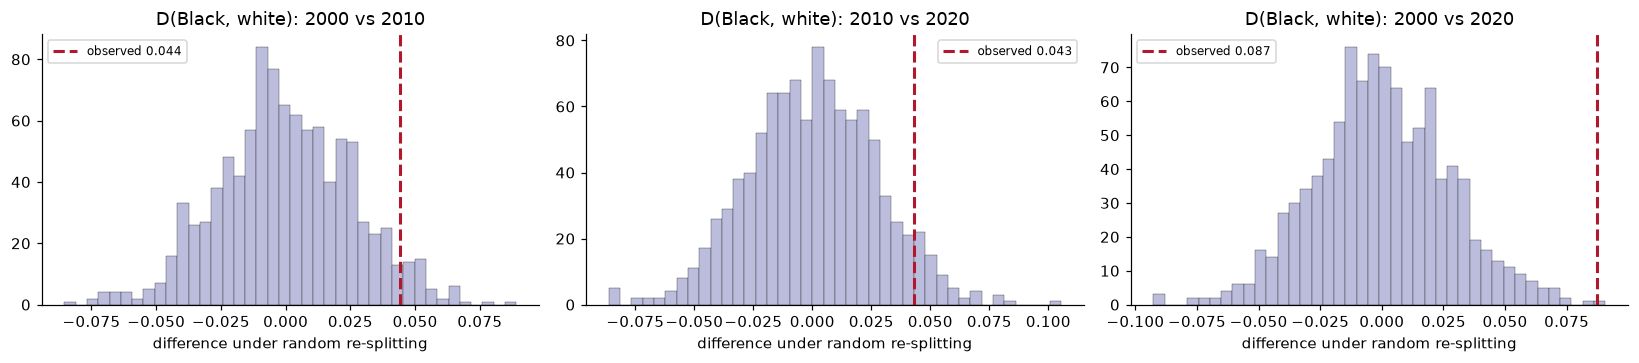

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))  # create figure and axes
for ax, (a, b) in zip(axes, comparisons):  # pair each axis with a year or layer
    r = null_diffs[(a, b, "dissimilarity")]  # compute() result with value and CI
    ax.hist(r["null_distribution"], bins=40, color="#bcbddc", edgecolor="k", lw=0.2)  # run this analysis or plotting step
    ax.axvline(r["difference"], color="#b2182b", lw=2, ls="--", label=f"observed {r['difference']:.3f}")  # run this analysis or plotting step
    ax.set(title=f"D(Black, white): {a} vs {b}", xlabel="difference under random re-splitting"); ax.legend(fontsize=8)  # add a legend
plt.tight_layout(); plt.show()  # render the figure in the notebook



Only the 20-year comparison is clearly significant for dissimilarity (p = 0.005); the decade-by-
decade declines of about 0.04 each have p-values of 0.09 and 0.11. Theil's $H$ falls more and its
decade changes reach p < 0.05. With a decline this gradual, a test that ignores the pairing of tracts
has little power, which the next caveat explains.

> **Caveat.** This test treats the two datasets as independent samples of tracts. Here the same
> 323 tracts appear in both years, so the units are paired, and the test ignores that pairing as
> well as spatial dependence. It is the test PySAL implements, and a reasonable screen, but the
> paired block bootstrap in Part D is a better match for a same-tract panel.

## Part C: Confidence intervals that respect space

### C1. Unit bootstrap vs. block bootstrap

A **unit bootstrap** resamples the 323 tracts with replacement. A **spatial block bootstrap**
(`seg.spatial_block_bootstrap`) first groups tracts into spatial blocks, then resamples whole
blocks. Because tract compositions are strongly autocorrelated, neighbouring tracts carry
overlapping information; the unit bootstrap counts them as independent and produces intervals
that are too narrow.






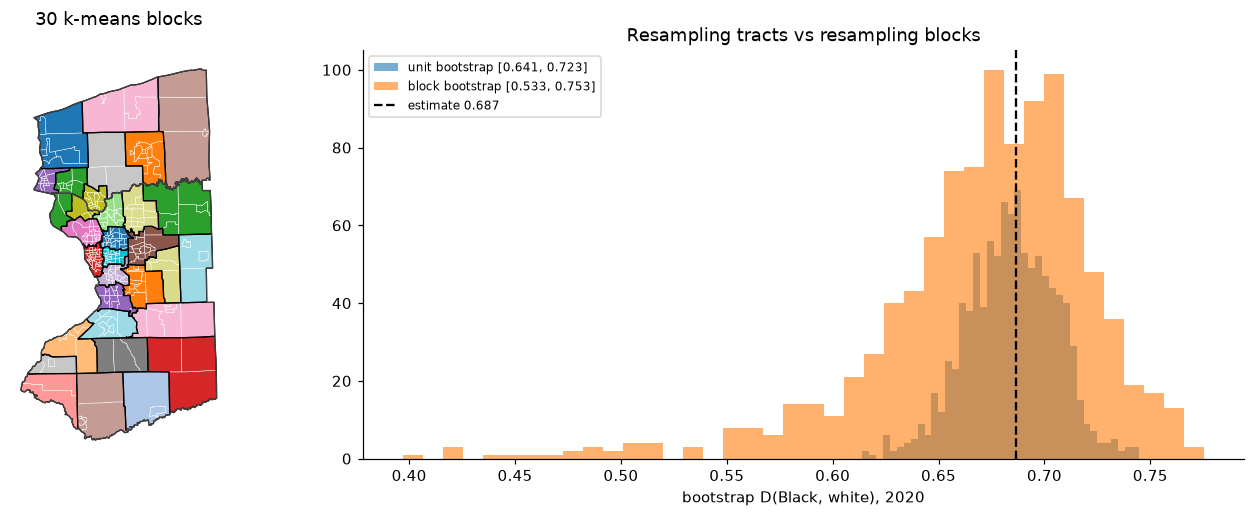

interval width ratio (block / unit): 2.67
bootstrap medians: unit 0.685, block 0.678 (estimate 0.687)


In [6]:
# ===================================================================
# Part C: Confidence intervals that respect space.
# Only the 20-year comparison is clearly significant for dissimilarity (p = 0.005); the decade-by-
# ===================================================================

def unit_bootstrap(gdf, groups, index_fn, n_boot=999, ci=0.95, seed=0, **kw):
    rng = np.random.default_rng(seed)  # reproducible random generator
    n = len(gdf)  # define n
    vals = np.array([index_fn(gdf.iloc[rng.integers(0, n, n)], groups, **kw) for _ in range(n_boot)])  # define vals
    lo, hi = np.quantile(vals, [(1 - ci) / 2, 1 - (1 - ci) / 2])  # run this analysis or plotting step
    return {"estimate": index_fn(gdf, groups, **kw), "ci_lower": lo, "ci_upper": hi, "boot_distribution": vals}  # return the computed result

y = 2020  # panel year
ub = unit_bootstrap(tracts[y], pair, seg.dissimilarity, seed=3)  # define ub
bb = seg.spatial_block_bootstrap(tracts[y], pair, seg.dissimilarity, n_boot=999, n_blocks=30, seed=3)  # define bb

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [0.8, 1.3]})  # create figure and axes
tracts[y].assign(b=bb["blocks"]).plot(column="b", categorical=True, cmap="tab20", ax=axes[0], edgecolor="white", lw=0.3)  # draw geometries or a series on the axes
tracts[y].dissolve(by=bb["blocks"]).boundary.plot(ax=axes[0], color="k", lw=0.8)  # draw geometries or a series on the axes
add_context(axes[0], labels=False); axes[0].set_title("30 k-means blocks")  # county outlines and optional city zoom
axes[1].hist(ub["boot_distribution"], bins=40, alpha=0.6, label=f"unit bootstrap [{ub['ci_lower']:.3f}, {ub['ci_upper']:.3f}]")  # run this analysis or plotting step
axes[1].hist(bb["boot_distribution"], bins=40, alpha=0.6, label=f"block bootstrap [{bb['ci_lower']:.3f}, {bb['ci_upper']:.3f}]")  # run this analysis or plotting step
axes[1].axvline(bb["estimate"], color="k", ls="--", lw=1.5, label=f"estimate {bb['estimate']:.3f}")  # run this analysis or plotting step
axes[1].set(xlabel="bootstrap D(Black, white), 2020", title="Resampling tracts vs resampling blocks"); axes[1].legend(fontsize=8)  # add a legend
plt.tight_layout(); plt.show()  # render the figure in the notebook
print(f"interval width ratio (block / unit): {(bb['ci_upper'] - bb['ci_lower']) / (ub['ci_upper'] - ub['ci_lower']):.2f}")  # status line for the notebook reader
print(f"bootstrap medians: unit {np.median(ub['boot_distribution']):.3f}, block {np.median(bb['boot_distribution']):.3f} (estimate {bb['estimate']:.3f})")  # status line for the notebook reader



The block-bootstrap interval is about 2.7 times wider than the unit-bootstrap interval. Resampling
a block pulls in a whole run of similarly composed tracts, which is how the real uncertainty
behaves when the pattern is spatially smooth. Both bootstrap distributions are centred close to
the estimate here, but they are skewed to the left: replicates that happen to include few East Side
tracts produce a much lower $D$.

### C2. How many blocks?

Fewer, larger blocks preserve more dependence but leave few resampling units. In Buffalo there
is a second issue: if the blocks are large, one block may hold most of a group. Replicates that
leave that block out describe a different metro area altogether. The table reports, for each block
count, the largest share of Black residents in any single block.






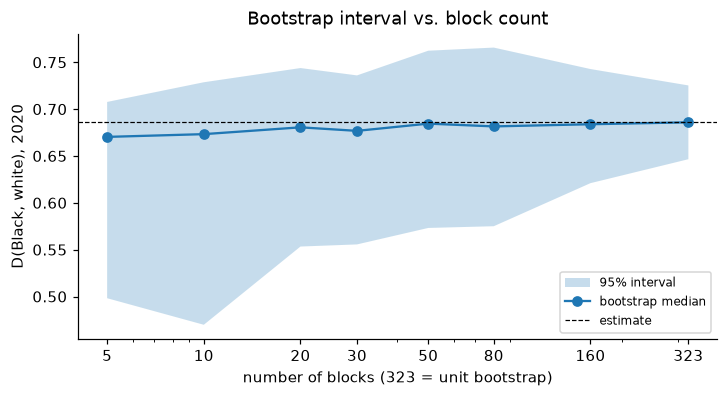

,largest block's share of Black residents,ci_lower,ci_upper,width,boot median
blocks,,,,,
5,0.807,0.498,0.708,0.209,0.670
10,0.702,0.470,0.729,0.259,0.673
20,0.240,0.553,0.744,0.190,0.681
30,0.242,0.556,0.736,0.180,0.677
50,0.207,0.573,0.762,0.189,0.685
80,0.195,0.575,0.766,0.191,0.682
160,0.080,0.621,0.743,0.122,0.684
323,0.030,0.647,0.725,0.079,0.686


In [7]:
# ===================================================================
# C2. How many blocks?.
# The block-bootstrap interval is about 2.7 times wider than the unit-bootstrap interval. Resampling
# ===================================================================

rows = []  # accumulate one summary row per year / group
for k in [5, 10, 20, 30, 50, 80, 160, 323]:  # iterate over the collection
    if k == 323:  # conditional branch
        r = unit_bootstrap(tracts[2020], pair, seg.dissimilarity, n_boot=499, seed=0)  # compute() result with value and CI
        top = tracts[2020].black.max() / tracts[2020].black.sum()  # sum the selected values
    else:
        r = seg.spatial_block_bootstrap(tracts[2020], pair, seg.dissimilarity, n_boot=499, n_blocks=k, seed=0)  # compute() result with value and CI
        top = (tracts[2020].black.groupby(r["blocks"]).sum() / tracts[2020].black.sum()).max()  # sum the selected values
    rows.append({"blocks": k, "largest block's share of Black residents": top,  # append this year/group record
                 "ci_lower": r["ci_lower"], "ci_upper": r["ci_upper"],
                 "width": r["ci_upper"] - r["ci_lower"], "boot median": np.median(r["boot_distribution"])})  # run this analysis or plotting step
blk = pd.DataFrame(rows).set_index("blocks")  # build table blk

fig, ax = plt.subplots(figsize=(7.5, 3.6))  # create figure and axes
ax.fill_between(blk.index, blk.ci_lower, blk.ci_upper, alpha=0.25, label="95% interval")  # run this analysis or plotting step
ax.plot(blk.index, blk["boot median"], marker="o", label="bootstrap median")  # draw geometries or a series on the axes
ax.axhline(seg.dissimilarity(tracts[2020], pair), color="k", ls="--", lw=0.8, label="estimate")  # two-group dissimilarity index D
ax.set(xscale="log", xlabel="number of blocks (323 = unit bootstrap)", ylabel="D(Black, white), 2020",  # set labels, title, or axis limits
       title="Bootstrap interval vs. block count")  # define title
ax.set_xticks(blk.index, blk.index); ax.legend(fontsize=8); plt.show()  # render the figure in the notebook
blk.round(3)  # round for readable display


With 5 or 10 blocks, a single block holds 70% to 80% of the metro area's Black residents. Every
replicate that draws that block zero times describes a metro area with almost no Black population,
so the interval stretches far down and is lopsided. From about 20 blocks the largest block's share
falls to about a quarter and the interval stabilizes at roughly 0.55 to 0.75. With many very small
blocks it narrows toward the unit bootstrap, which ignores spatial dependence. For Buffalo, 20 to 50
blocks is a defensible range; this series uses 30. Report the block count and check that
conclusions hold across the stable range.

## Part D: A paired block bootstrap for change

When both years use the same tracts, resample the **same blocks** for both years in each replicate
and compute the difference. This keeps the pairing (each tract compared with itself) and the
spatial dependence, and gives a confidence interval for the change directly. Because the same
tracts drop in or out of both years together, the "missing East Side" problem of Part C largely
cancels.






In [8]:
# ===================================================================
# Part D: A paired block bootstrap for change.
# With 5 or 10 blocks, a single block holds 70% to 80% of the metro area's Black residents. Every
# ===================================================================

def paired_block_change(gdf_a, gdf_b, groups, index_fn, n_boot=999, n_blocks=30, seed=0, ci=0.95):
    rng = np.random.default_rng(seed)  # reproducible random generator
    blocks = seg.spatial_blocks(gdf_a, n_blocks=n_blocks, seed=seed)  # define blocks
    ub = np.unique(blocks)  # define ub
    members = {b_: np.where(blocks == b_)[0] for b_ in ub}  # define members
    diffs = np.empty(n_boot)  # define diffs
    for i in range(n_boot):  # iterate over the collection
        rows_ = np.concatenate([members[b_] for b_ in rng.choice(ub, size=len(ub), replace=True)])  # define rows_
        diffs[i] = index_fn(gdf_b.iloc[rows_], groups) - index_fn(gdf_a.iloc[rows_], groups)  # absolute gap between group share schedules
    est = index_fn(gdf_b, groups) - index_fn(gdf_a, groups)  # define est
    lo, hi = np.quantile(diffs, [(1 - ci) / 2, 1 - (1 - ci) / 2])  # run this analysis or plotting step
    return {"change": est, "ci_lower": lo, "ci_upper": hi, "share of replicates < 0": (diffs < 0).mean()}  # return the computed result

rows = []  # accumulate one summary row per year / group
for a, b in comparisons:  # iterate over the collection
    for name, fn, grp in [("D Black-white", seg.dissimilarity, pair), ("D Asian-white", seg.dissimilarity, ["asian", "white"]),  # loop over group pairs
                          ("Theil H", seg.theil_h, GROUPS)]:  # run this analysis or plotting step
        r = paired_block_change(tracts[a], tracts[b], grp, fn, n_blocks=30, seed=0)  # compute() result with value and CI
        rows.append({"index": name, "period": f"{a} to {b}", **r})  # append this year/group record
pd.DataFrame(rows).set_index(["index", "period"]).round(4)  # run this analysis or plotting step



,,change,ci_lower,ci_upper,share of replicates < 0
index,period,,,,
D Black-white,2000 to 2010,-0.0441,-0.0914,-0.0147,1.000
D Asian-white,2000 to 2010,0.0458,0.0114,0.1002,0.003
Theil H,2000 to 2010,-0.0653,-0.0897,-0.0319,1.000
D Black-white,2010 to 2020,-0.0432,-0.0683,-0.0118,0.997
D Asian-white,2010 to 2020,0.0397,-0.0038,0.1194,0.042
Theil H,2010 to 2020,-0.0624,-0.0803,-0.0228,0.999
D Black-white,2000 to 2020,-0.0873,-0.1466,-0.0371,1.000
D Asian-white,2000 to 2020,0.0855,0.0175,0.1994,0.011
Theil H,2000 to 2020,-0.1276,-0.1618,-0.0603,1.000


The paired bootstrap gives a much sharper answer than Part B:

- **Black-white** dissimilarity declined significantly in *each* decade (intervals exclude zero,
  and 99.7% or more of replicates show a decline), about 0.04 per decade and 0.09 over 20 years.
- **Asian-white** dissimilarity rose significantly between 2000 and 2010 and over the whole
  20 years. For 2010 to 2020 the interval just includes zero (4% of replicates show a decline),
  so the second-decade rise is likely but less certain. The Asian intervals are wide because the
  group is small.
- **Theil's $H$** fell significantly in each decade.

Pairing removes the tract-to-tract variation that both years share. This is the recommended way to
report change on a fixed-boundary panel.

## Part E: Trend tests on a short panel

`seg.panel_trend_test` runs a Mann-Kendall test (non-parametric: it only uses the signs of
pairwise differences) and reports the Theil-Sen slope (median of pairwise slopes). It needs at
least three periods. With census data the panel is short, which limits power severely: even a
perfectly monotone series cannot reach a small p-value with few periods.






In [9]:
# ===================================================================
# Part E: Trend tests on a short panel.
# The paired bootstrap gives a much sharper answer than Part B:
# ===================================================================

panel_vals = [seg.dissimilarity(tracts[y], pair) for y in YEARS]  # two-group dissimilarity index D
tr = seg.panel_trend_test(panel_vals, periods=list(YEARS))  # define tr
print({k: (round(v, 5) if isinstance(v, float) else v) for k, v in tr.items()})  # status line for the notebook reader

rows = []  # accumulate one summary row per year / group
for n in range(3, 11):  # iterate over the collection
    perfect = seg.panel_trend_test(np.arange(n, 0, -1), periods=np.arange(n))  # numeric grid for plotting or thresholds
    rows.append({"periods": n, "smallest possible p (perfect monotone trend)": perfect["p_value"]})  # append this year/group record
pd.DataFrame(rows).set_index("periods").round(4)  # run this analysis or plotting step



{'tau': -1.0, 'z': -1.04447, 'p_value': 0.29627, 'trend': 'decreasing', 'sen_slope': -0.00437}


,smallest possible p (perfect monotone trend)
periods,
3,0.2963
4,0.0894
5,0.0275
6,0.0085
7,0.0027
8,0.0008
9,0.0003
10,0.0001


With three census years the Mann-Kendall p-value can never fall below about 0.30, even for a
perfectly monotone decline like Buffalo's; with four it cannot reach 0.05. For a short panel:

- Report the **Sen slope** as the effect size (here about $-0.0044$ per year, or $-0.044$ per decade).
- Use the **paired block bootstrap** (Part D) to establish that each change is real.
- Add periods where possible: American Community Survey 5-year estimates give annual tract data
  since 2009 (with sampling error that must be carried into the analysis), and older censuses can
  be interpolated onto current tracts as in notebook 03_07_07.

## Part F: A reporting table

Pulling the pieces together for the Black-white dissimilarity index:






In [10]:
# ===================================================================
# Part F: A reporting table.
# With three census years the Mann-Kendall p-value can never fall below about 0.30, even for a
# ===================================================================

rows = []  # accumulate one summary row per year / group
for y in YEARS:  # loop over panel years
    bb_ = seg.spatial_block_bootstrap(tracts[y], pair, seg.dissimilarity, n_boot=999, n_blocks=30, seed=0)  # define bb_
    sv = store[(y, "dissimilarity")]  # define sv
    rows.append({"year": y, "D": bb_["estimate"],  # append this year/group record
                 "95% CI (block bootstrap, 30 blocks)": f"[{bb_['ci_lower']:.3f}, {bb_['ci_upper']:.3f}]",  # run this analysis or plotting step
                 "bias-corrected D": bb_["estimate"] - sv["null_mean"],
                 "p vs evenness": sv["p_value"]})
report = pd.DataFrame(rows).set_index("year")  # build table report
display(report.round(3))  # show a rich table preview
ch = paired_block_change(tracts[2000], tracts[2020], pair, seg.dissimilarity, n_blocks=30, seed=0)  # define ch
print(f"Change 2000 to 2020: {ch['change']:.3f} (95% paired block-bootstrap CI {ch['ci_lower']:.3f} to {ch['ci_upper']:.3f}); "  # status line for the notebook reader
      f"Sen slope {tr['sen_slope'] * 10:.3f} per decade")


,D,"95% CI (block bootstrap, 30 blocks)",bias-corrected D,p vs evenness
year,,,,
2000,0.774,"[0.651, 0.823]",0.754,0.002
2010,0.730,"[0.593, 0.781]",0.710,0.002
2020,0.687,"[0.563, 0.740]",0.667,0.002


Change 2000 to 2020: -0.087 (95% paired block-bootstrap CI -0.147 to -0.037); Sen slope -0.044 per decade


## Summary

- **Single-value tests** compare an index with a null. Use the evenness null for aspatial indices
  and the systematic null for spatial ones; with tracts of thousands of people, focus on the effect
  size rather than the (always tiny) p-value.
- **Two-sample permutation tests** compare two datasets but ignore pairing and spatial dependence.
- The **unit bootstrap** understates uncertainty when compositions are spatially autocorrelated;
  the **spatial block bootstrap** gives wider, more honest intervals. When one group lives in a
  small part of the map, large blocks give unstable, skewed intervals. Report the number of blocks
  and how much of each group the largest block holds.
- For a fixed-boundary panel, a **paired block bootstrap** of the change is the most direct way
  to show that segregation moved.
- **Mann-Kendall** trend tests have almost no power with three or four census years. Report the
  Sen slope and bootstrap evidence, and extend the panel where possible.

**Next:** 03_07_07 harmonizes census boundaries across years and decomposes change into spatial
and compositional parts.

## References

- Hamed, K. H., & Rao, A. R. (1998). A modified Mann-Kendall trend test for autocorrelated data. *Journal of Hydrology*, 204(1-4), 182-196.
- Lahiri, S. N. (2003). *Resampling Methods for Dependent Data*. Springer.
- Rey, S. J., & Folch, D. C. (2011). Impact of spatial effects on income segregation indices. *Computers, Environment and Urban Systems*, 35(6), 431-441.
- Sen, P. K. (1968). Estimates of the regression coefficient based on Kendall's tau. *Journal of the American Statistical Association*, 63(324), 1379-1389.
- Cortes, R. X., Rey, S., Knaap, E., & Wolf, L. J. (2020). An open-source framework for non-spatial and spatial segregation measures: the PySAL segregation module. *Journal of Computational Social Science*, 3, 135-166.




